First 5 Rows:
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Si

C:\Users\aswat\AppData\Local\Temp\ipykernel_29196\969294928.py:25: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object", "category"]).columns:


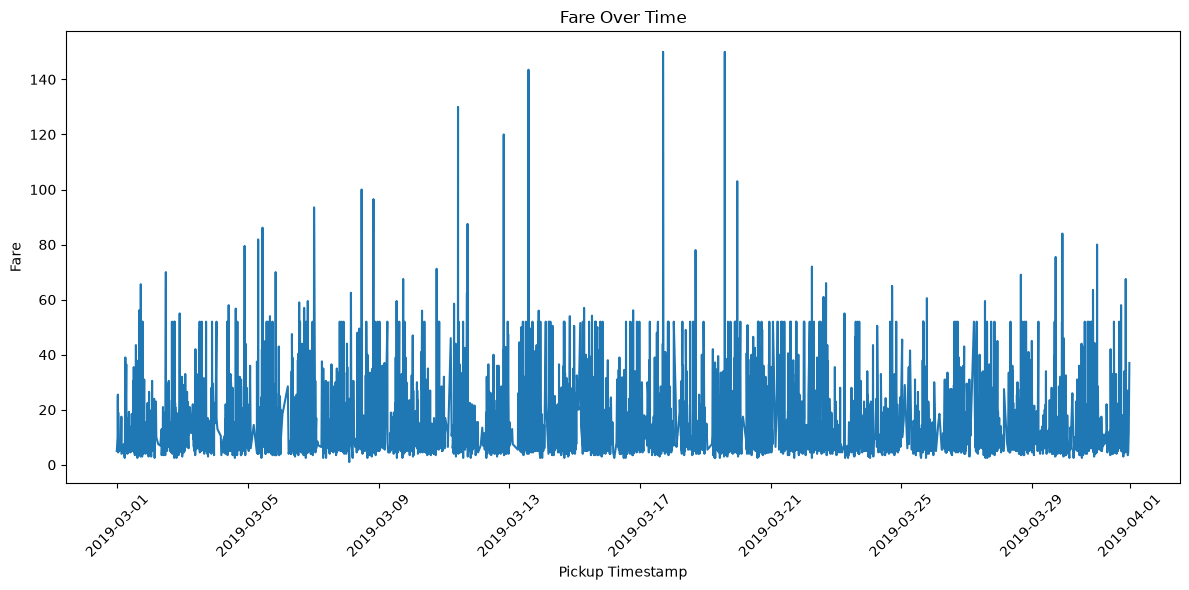

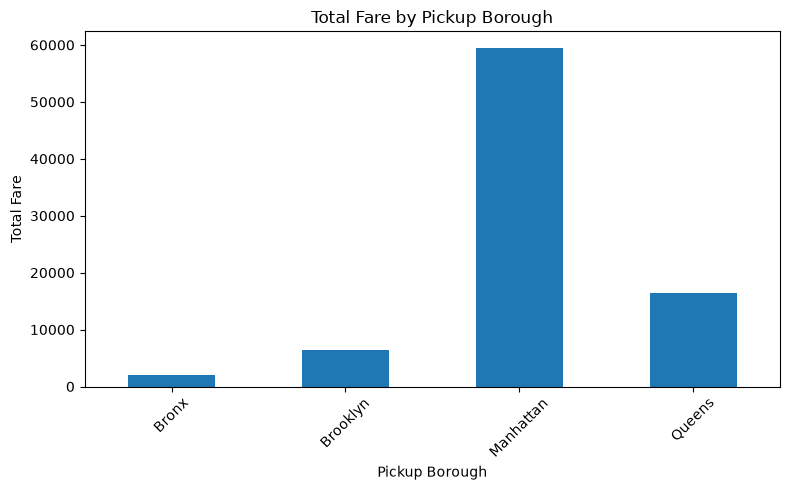

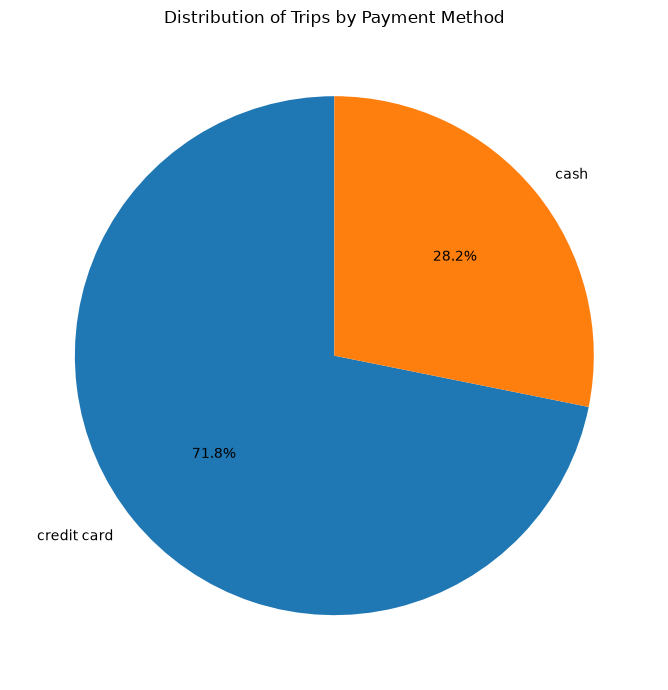

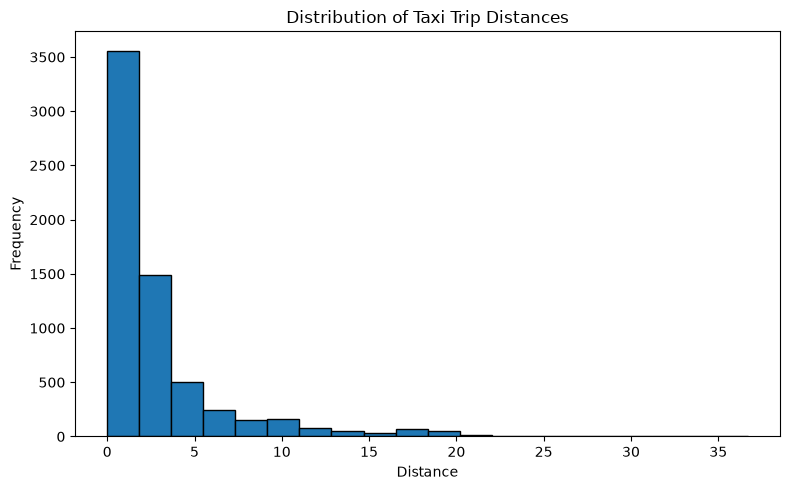

<Figure size 1000x600 with 0 Axes>

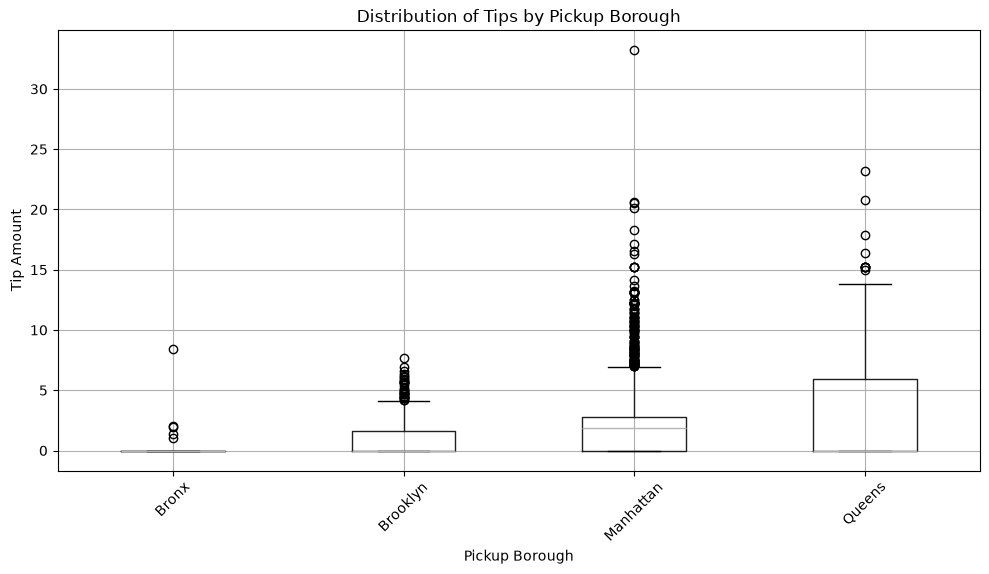

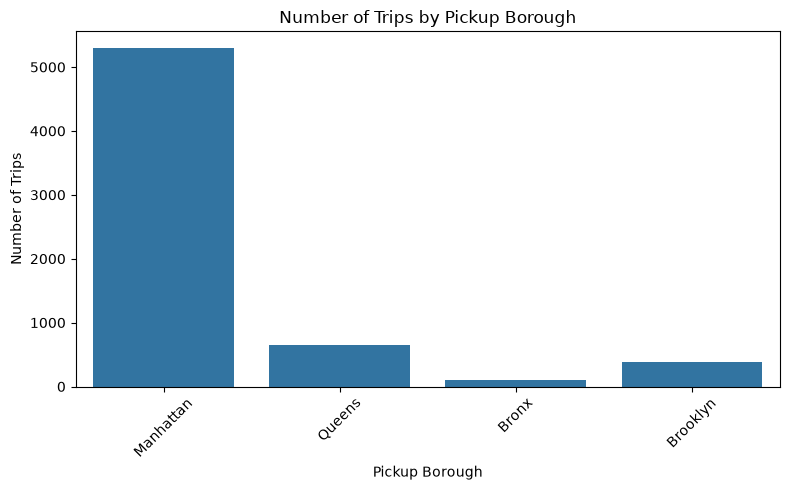

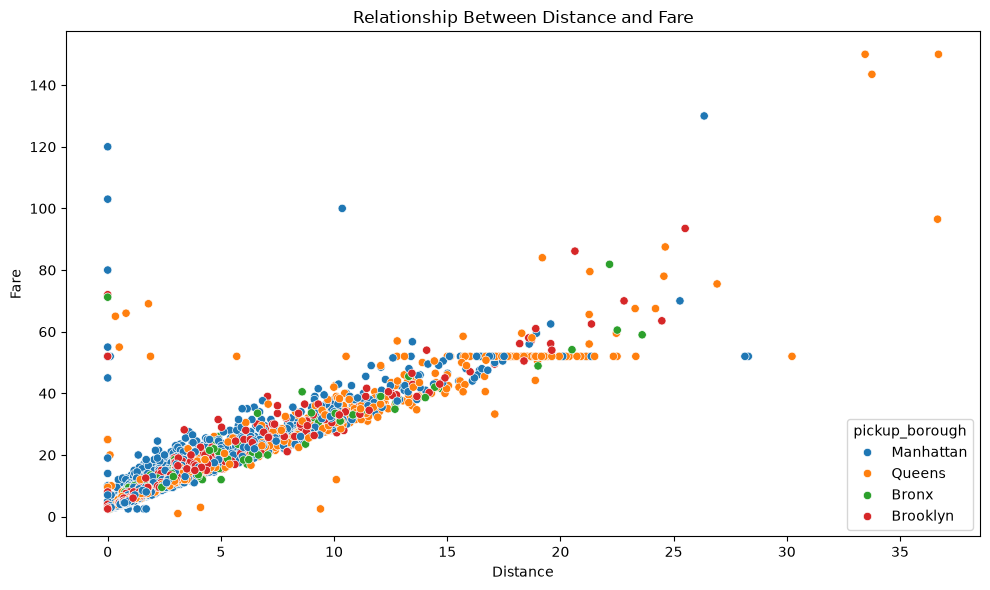

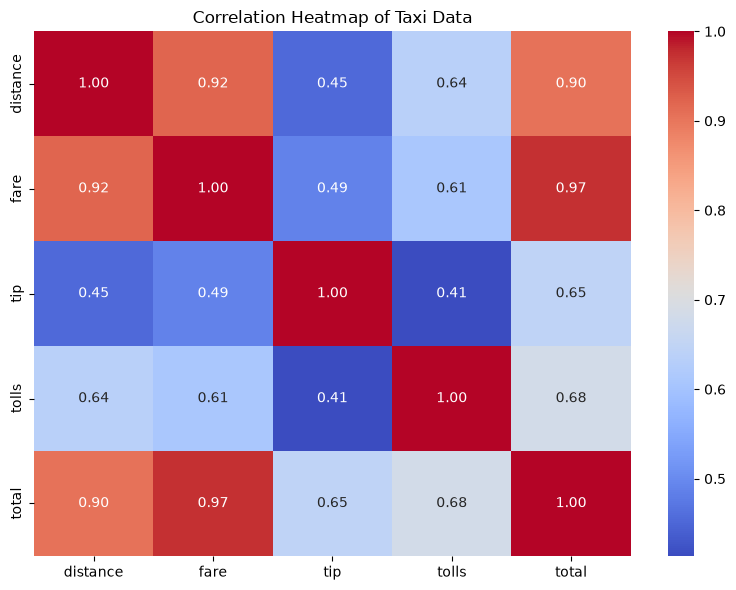

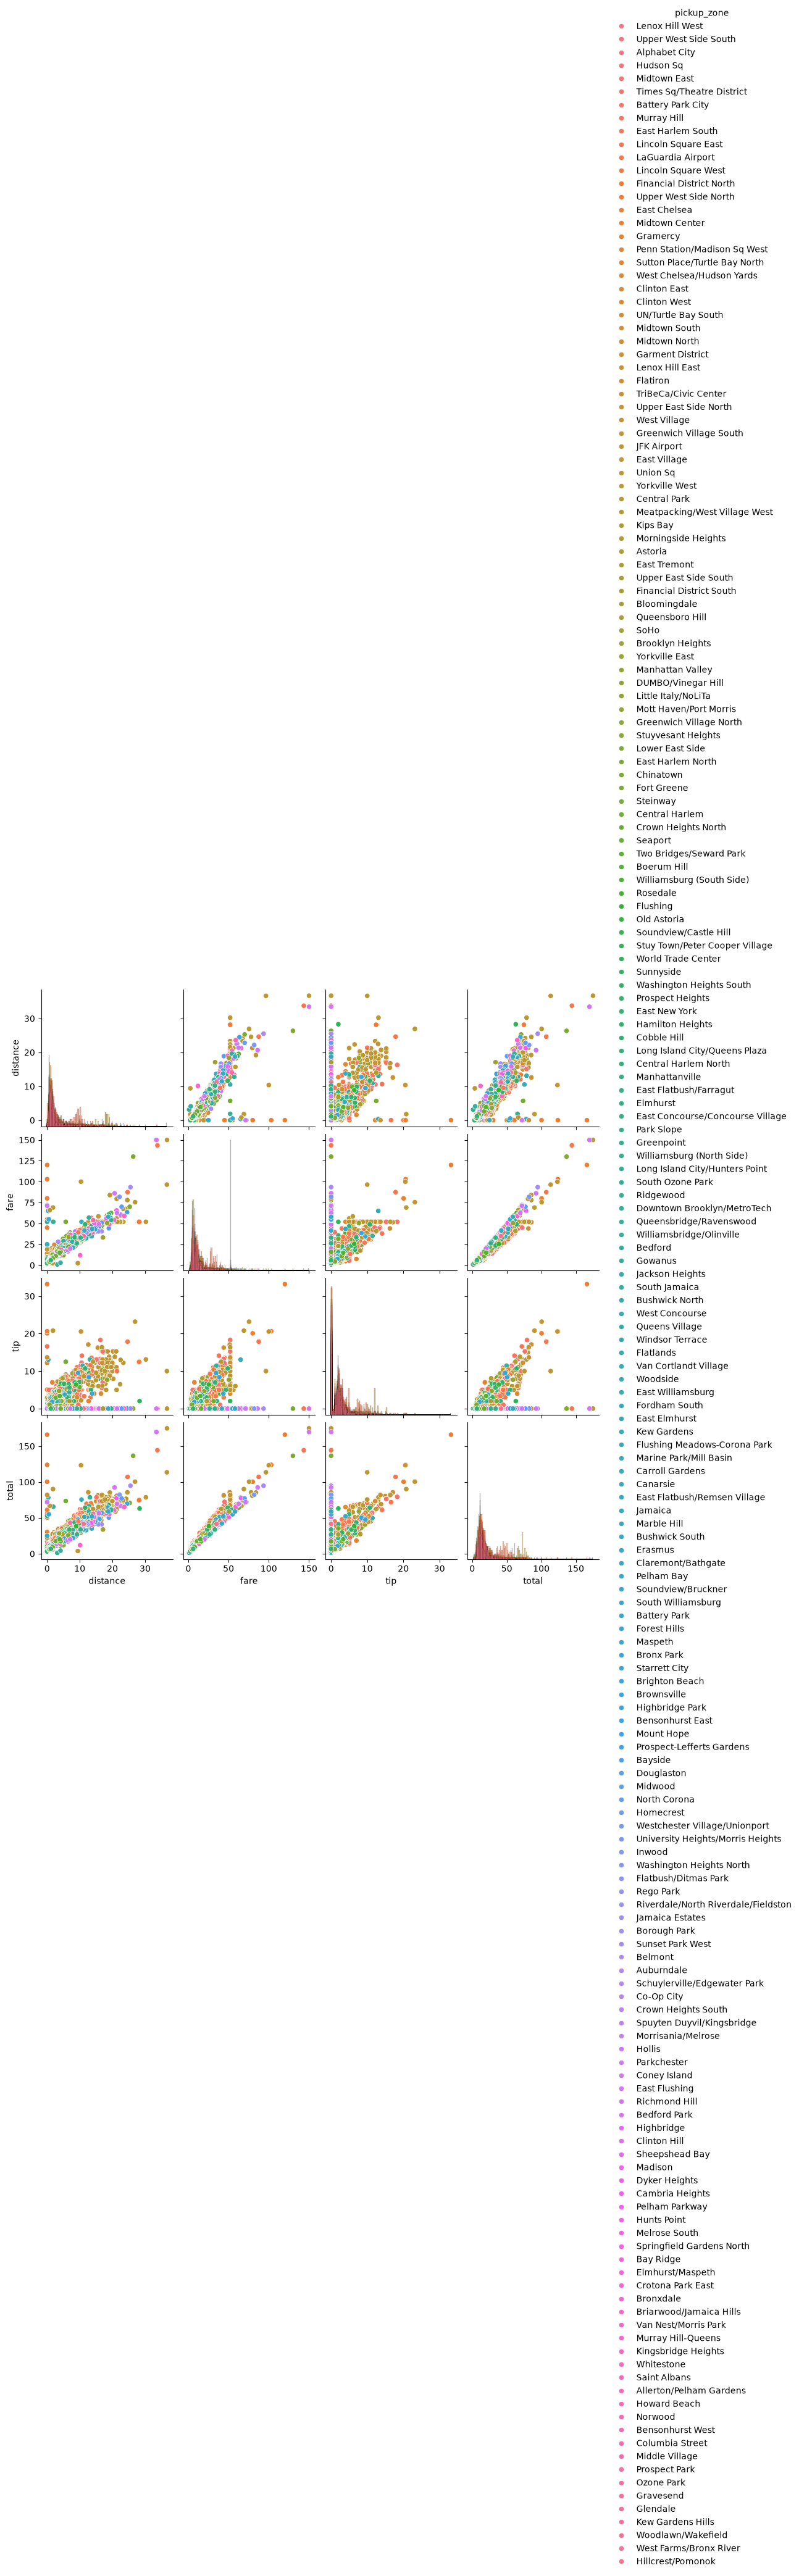

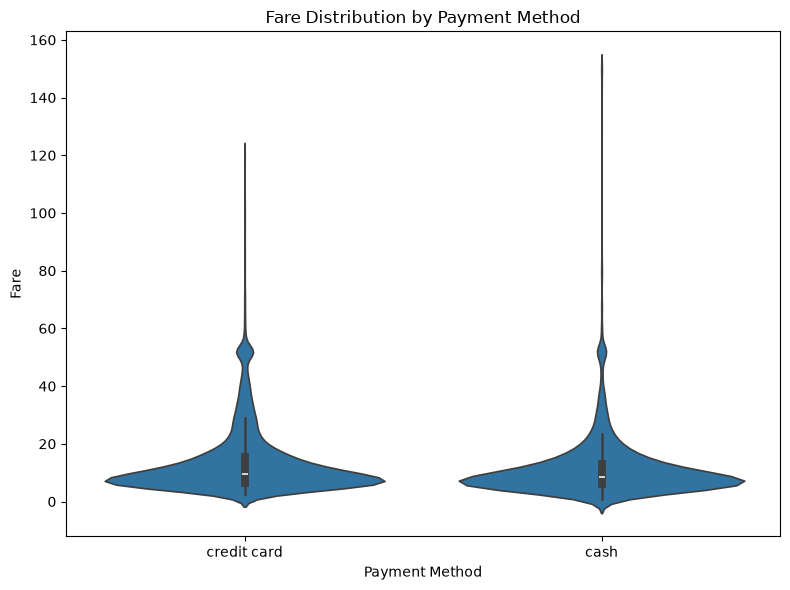


Python DA Assignment 2 Completed Successfully!


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values Before Handling:")
print(df.isnull().sum())

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object", "category"]).columns:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values[0])
df = df.dropna(
    subset=[
        "pickup",
        "fare",
        "pickup_borough",
        "payment",
        "distance",
        "tip",
        "tolls",
        "total",
        "pickup_zone"
    ]
)

print("\nMissing Values After Handling:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:")
print(df.shape)

df["pickup"] = pd.to_datetime(df["pickup"])

line_df = df.sort_values("pickup")

plt.figure(figsize=(12, 6))
plt.plot(line_df["pickup"], line_df["fare"])

plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.title("Fare Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

borough_fare = df.groupby("pickup_borough")["fare"].sum()

plt.figure(figsize=(8, 5))
borough_fare.plot(kind="bar")

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

payment_counts = df["payment"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

plt.hist(
    df["distance"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Taxi Trip Distances")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

df.boxplot(
    column="tip",
    by="pickup_borough",
    figsize=(10, 6)
)

plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Distribution of Tips by Pickup Borough")
plt.suptitle("")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="pickup_borough"
)

plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Pickup Borough")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)

plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Relationship Between Distance and Fare")
plt.tight_layout()
plt.show()

numeric_df = df[
    ["distance", "fare", "tip", "tolls", "total"]
]

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Taxi Data")
plt.tight_layout()
plt.show()

pair_df = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()

sns.pairplot(
    pair_df,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist"
)

plt.show()

plt.figure(figsize=(8, 6))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)

plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.title("Fare Distribution by Payment Method")
plt.tight_layout()
plt.show()

print("\nPython DA Assignment 2 Completed Successfully!")